# 02 — Limpeza, divisão sem vazamento e extração de características

1. Integridade e duplicatas (MD5 + dHash). 2. Divisão 71/14/14% **estratificada por classe e agrupada por folha** (PlantVillage fotografa a mesma folha várias vezes). 3. Descritores clássicos (30) e embeddings MobileNetV2 (1984-d multiescala).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
M = ROOT / 'results' / 'metrics'
def show(name): display(Image(filename=str(ROOT / 'results' / name), width=620))


{
 "dataset": "PlantVillage (color) — Hughes & Salathé 2015 / Mohanty et al. 2016, 6 classes",
 "cleaning": {
  "total_listed": 7692,
  "corrupted_removed": 0,
  "exact_duplicates_removed": 14,
  "near_duplicates_removed": 0,
  "valid_unique_images": 7678,
  "per_class_after_cleaning": {
   "Tomato___Early_blight": 1000,
   "Tomato___Late_blight": 1901,
   "Tomato___healthy": 1585,
   "Potato___Early_blight": 1000,
   "Potato___Late_blight": 1000,
   "Corn_(maize)___Common_rust_": 1192
  }
 },
 "images_with_leaf_group": 4918,
 "unique_groups": 3956,
 "train_count": 5484,
 "val_count": 1097,
 "test_count": 1097,
 "proportions": {
  "train": 0.7142,
  "val": 0.1429,
  "test": 0.1429
 },
 "class_distribution_train": {
  "Corn_(maize)___Common_rust_": 852,
  "Potato___Early_blight": 712,
  "Potato___Late_blight": 716,
  "Tomato___Early_blight": 715,
  "Tomato___Late_blight": 1357,
  "Tomato___healthy": 1132
 },
 "class_distribution_val": {
  "Corn_(maize)___Common_rust_": 170,
  "Potato___

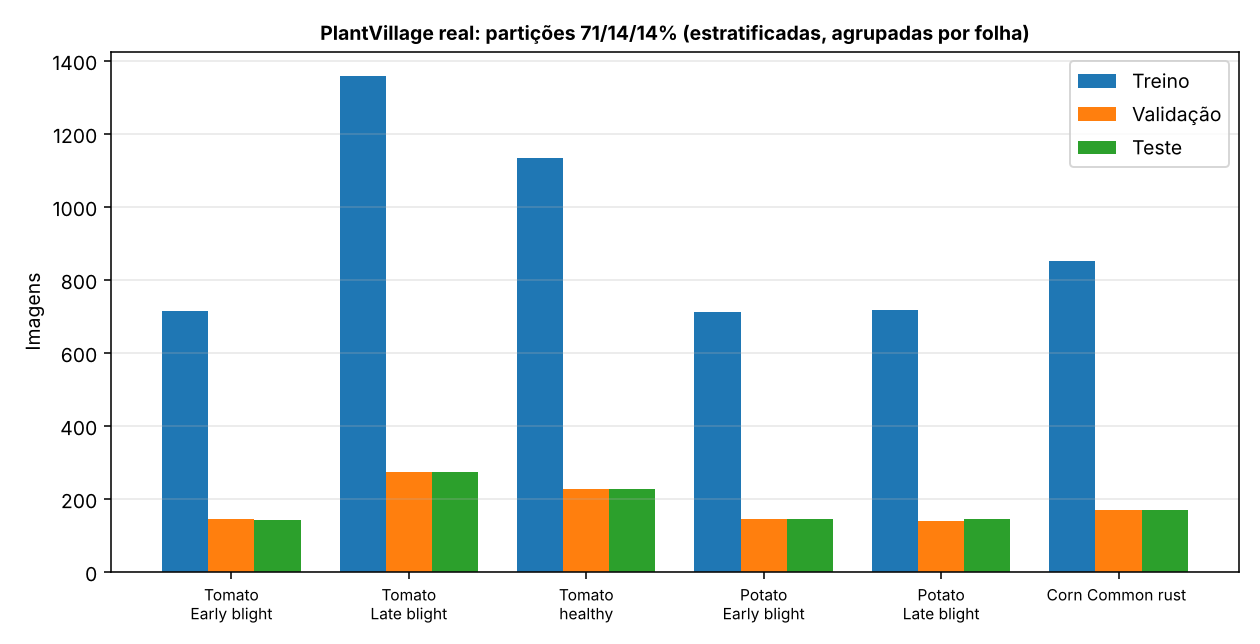

In [2]:
print(json.dumps(json.load(open(M/'dataset_split_70_15_15.json')), indent=1, ensure_ascii=False)[:2500]); show('plots/dataset_class_distribution.png')

In [3]:
from src.vision.image_processor import ImageProcessor
proc = ImageProcessor(); res = proc.process(ROOT/'results'/'exemplos'/'plantvillage_Tomato_Early_blight.jpg')
print('válida:', res.is_valid, '| brilho: %.1f | nitidez: %.1f' % (res.brightness, res.blur_score), '| padrões:', res.detected_visual_patterns)
print('vetor de descritores:', res.feature_vector.shape, '| tensor:', res.tensor.shape, res.tensor.min(), res.tensor.max())

válida: True | brilho: 103.9 | nitidez: 1128.9 | padrões: ['lesoes_escuras_encharcadas']
vetor de descritores: (30,) | tensor: (1, 224, 224, 3) 0.0 0.8627451


In [4]:
# Qualidade das imagens REAIS (mesmos limiares das regras de decisão)
f = np.load(ROOT/'results'/'cache'/'plantvillage_features.npz'); g = np.load(ROOT/'results'/'cache'/'plantdoc_features.npz')
for name, d in (('PlantVillage', f), ('PlantDoc', g)):
    print(f"{name}: brilho médio={d['brightness'].mean():.1f} | nitidez mediana={np.median(d['blur_score']):.1f} | rejeitadas por qualidade={(d['blur_score']<18).sum()+(d['brightness']<25).sum()} / {len(d['blur_score'])}")

PlantVillage: brilho médio=113.9 | nitidez mediana=997.1 | rejeitadas por qualidade=48 / 7678
PlantDoc: brilho médio=119.3 | nitidez mediana=579.1 | rejeitadas por qualidade=0 / 586
